In [ ]:
from pathlib import Path

import cmocean
import jax
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.colocalization.costes import (
    colocalization_costes,
)
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.utils.io import read_SIM_data
from einops import rearrange
from IPython.display import display, SVG
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator


datadir = Path("../../data/SIM")


"""Independent intensity histograms with Costes exclusion regions.

Consumes the existing data_chunk_dict and results_dict; does not rerun the
Costes calculation. Uses one independent log count scale/colorbar per panel.
Default: show counts of voxels above BOTH supplied channel thresholds and
cover excluded intensity regions with opaque light gray.
"""


def make_costes_histogram_panel(
    data_chunk_dict,
    results_dict,
    *,
    chunk_idx=0,
    proteins=("actin", "actinin", "myosin"),
    bins=100,
    figsize=(12, 4.3),
    cmap=None,
    pale_cut=0.08,
    retained_only=True,
    excluded_color="#DEDEDE",
    excluded_alpha=1.0,
    font_size=14,
    tick_size=11,
    colorbar_fontsize=11,
    wspace=0.22,
    threshold_linewidth=1.0,
):
    """Return (fig, axes, details), keeping every panel's scaling independent.

    Channel 0 is Desmin; channel 1 is the partner protein. Actin's channel
    reversal must already have been performed by your existing data loading.

    Exclusion rule, matching the union of your two shaded strips:
        exclude x < t OR y < (a*t+b)
        retain  x >= t AND y >= (a*t+b)
    This display rule is explicit; change it if your analysis uses another
    boundary convention. The results_dict thresholds are never recomputed.

    retained_only=True: bin only retained voxels, using the bin edges obtained
    from the full chunk, and normalize to that histogram's maximum. Excluded
    background peaks cannot determine the useful color scale. The colorbar
    is labeled 'Retained voxels / bin'.
    retained_only=False: plot all voxel counts and use their maximum, matching
    the original hist2d count calculation. Set excluded_alpha=0.5 if context
    should remain visible through the gray cover.

    bins=100 yields independently chosen bin edges, as in the supplied code.
    No percentile clipping, smoothing or histogram equalization is applied.
    Empty bins are white. Default cmap is cmocean.ice_r (pale to dark blue);
    pale_cut omits a small near-white segment of the palette, not data values.
    Set pale_cut=0 for the unmodified palette. cmap may be a Matplotlib name
    or colormap object, e.g. cmocean.cm.dense for a purple alternative.
    """
    if not 0 <= pale_cut < 1:
        raise ValueError("pale_cut must be in [0, 1).")
    if not 0 <= excluded_alpha <= 1:
        raise ValueError("excluded_alpha must be in [0, 1].")
    proteins = tuple(proteins)
    if not proteins:
        raise ValueError("Supply at least one protein.")
    if cmap is None:
        import cmocean

        cmap = cmocean.cm.ice_r
    elif isinstance(cmap, str):
        cmap = mpl.colormaps[cmap]
    palette = ListedColormap(
        cmap(np.linspace(pale_cut, 1, 256)), name=f"{cmap.name}_display"
    )
    palette.set_bad("white")
    names = {"actin": "Actin", "actinin": "α-actinin", "myosin": "Myosin"}
    details = {}

    with plt.style.context("default"), mpl.rc_context({"font.size": font_size}):
        fig = plt.figure(figsize=figsize, layout="constrained")
        # A dedicated GridSpec row lets constrained layout reserve space for
        # top colorbar labels and titles, including in full-canvas exports.
        gs = fig.add_gridspec(
            2, len(proteins), height_ratios=(0.055, 1), wspace=wspace, hspace=0.02
        )
        axes = np.array([fig.add_subplot(gs[1, i]) for i in range(len(proteins))])
        for i, (protein, ax) in enumerate(zip(proteins, axes)):
            chunk = np.asarray(data_chunk_dict[protein][chunk_idx])
            x, y = chunk[0].ravel(), chunk[1].ravel()
            if (
                not x.size
                or x.shape != y.shape
                or not np.isfinite(x).all()
                or not np.isfinite(y).all()
            ):
                raise ValueError(
                    f"{protein}: expected matching nonempty finite channels."
                )
            results = results_dict[protein]
            tx = float(np.asarray(results["threshold"])[chunk_idx])
            slope = float(np.asarray(results["deming_slope"])[chunk_idx])
            intercept = float(np.asarray(results["deming_intercept"])[chunk_idx])
            ty = slope * tx + intercept
            if not np.isfinite([tx, ty]).all():
                raise ValueError(f"{protein}: thresholds must be finite.")

            all_counts, xe, ye = np.histogram2d(x, y, bins=bins)
            keep = (x >= tx) & (y >= ty)
            retained_counts, _, _ = np.histogram2d(x[keep], y[keep], bins=(xe, ye))
            counts = retained_counts if retained_only else all_counts
            # A maximum of 1 needs a nondegenerate log scale; no occupied bins
            # are discarded and all occupied count values remain represented.
            vmax = max(2.0, float(retained_counts.max()))
            norm = LogNorm(vmin=1, vmax=vmax)
            mesh = ax.pcolormesh(
                xe,
                ye,
                np.ma.masked_equal(counts.T, 0),
                cmap=palette,
                norm=norm,
                shading="flat",
                edgecolors="none",
                linewidth=0,
                antialiased=False,
                rasterized=True,
            )
            lo = min(xe[0], ye[0])
            hi = max(xe[-1], ye[-1])

            # Generate one set of evenly spaced ticks with convenient values.
            ticks = MaxNLocator(nbins=4).tick_values(lo, hi)

            xmin = ymin = ticks[0]
            xmax = ymax = ticks[-1]

            sx, sy = np.clip(tx, xmin, xmax), np.clip(ty, ymin, ymax)
            # Two NONOVERLAPPING rectangles make one uniformly shaded union.
            if sx > xmin:
                ax.add_patch(
                    Rectangle(
                        (xmin, ymin),
                        sx - xmin,
                        ymax - ymin,
                        facecolor=excluded_color,
                        edgecolor="none",
                        alpha=excluded_alpha,
                        zorder=2,
                    )
                )
            if sy > ymin and sx < xmax:
                ax.add_patch(
                    Rectangle(
                        (sx, ymin),
                        xmax - sx,
                        sy - ymin,
                        facecolor=excluded_color,
                        edgecolor="none",
                        alpha=excluded_alpha,
                        zorder=2,
                    )
                )

            lines = (
                ax.axvline(
                    tx, ls="--", color="black", lw=threshold_linewidth, zorder=3
                ),
                ax.axhline(
                    ty, ls="--", color="black", lw=threshold_linewidth, zorder=3
                ),
            )
            # Only the line styling belongs inside this loop.
            for line in lines:
                line.set_path_effects(
                    [
                        pe.Stroke(
                            linewidth=threshold_linewidth + 1.4, foreground="white"
                        ),
                        pe.Normal(),
                    ]
                )
            ax.set_xticks(ticks)
            ax.set_yticks(ticks)

            ax.set_xlim(xmin, xmax)
            ax.set_ylim(ymin, ymax)
            ax.set_xlabel("Intensity: Desmin")
            ax.set_ylabel(f"Intensity: {names.get(protein, protein)}")
            ax.tick_params(labelsize=tick_size)
            ax.set_aspect("equal", adjustable="box", anchor="N")

            ax.grid(False)
            if retained_only and not keep.any():
                ax.text(
                    0.5,
                    0.5,
                    "No retained voxels",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=tick_size,
                    zorder=4,
                )

            # Exactly one colorbar is created per histogram.
            cax = fig.add_subplot(gs[0, i])
            cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
            cax.tick_params(labelsize=colorbar_fontsize)
            cax.xaxis.set_ticks_position("top")
            cax.xaxis.set_label_position("top")
            label = "Pixel counts"
            cax.set_title(label + " (log scale)", fontsize=colorbar_fontsize, pad=6)
            details[protein] = {
                "thresholds": (tx, ty),
                "voxel_count": int(x.size),
                "retained_voxel_count": int(keep.sum()),
                "max_count_all": float(all_counts.max()),
                "max_count_retained": float(retained_counts.max()),
                "norm": norm,
                "colorbar": cbar,
                "mesh": mesh,
                "xedges": xe,
                "yedges": ye,
            }
    return fig, axes, details

In [17]:
filepath_dict = {
    "myosin": "myosin/Image20_myosin_SIM2.h5",
    "actin": "actin/Image10_actin_SIM2.h5",
    "actinin": "alpha-actinin/Image2_SIM2.h5",
}
roi_dict = {
    "myosin": np.s_[:, :, :, :],
    "actin": np.s_[::-1, :, 512:1536, 512:1536],
    "actinin": np.s_[:, :, 0:1024, 1024:2048],
}


In [ ]:
data_chunk_dict = {}
results_dict = {}

for protein in ("actin", "actinin", "myosin"):
    data, _ = read_SIM_data(datadir / filepath_dict[protein])
    data_chunks = rearrange(
        data[roi_dict[protein]], "C Z (Ny Y) (Nx X) -> (Ny Nx) C Z Y X", Ny=4, Nx=4
    )
    print(data_chunks.shape)
    data_chunk_dict[protein] = data_chunks

    results = jax.lax.map(
        lambda args: colocalization_costes(args[0], args[1]), data_chunks, batch_size=4
    )
    # print(results)
    results_dict[protein] = results

(16, 2, 45, 256, 256)
(16, 2, 45, 256, 256)
(16, 2, 39, 128, 128)


In [ ]:
fig, axes, details = make_costes_histogram_panel(
    data_chunk_dict,
    results_dict,
    chunk_idx=0,
    bins=100,
    figsize=(10, 4.3),
    wspace=0.02,
    cmap=cmocean.cm.ice_r,
    pale_cut=0.08,  # Keeps rare bins from becoming nearly white
    retained_only=False,
    excluded_color="#DEDEDE",
    excluded_alpha=0.5,  # Uniform gray; hides irrelevant data
    font_size=14,
    tick_size=11,
    colorbar_fontsize=11,
)


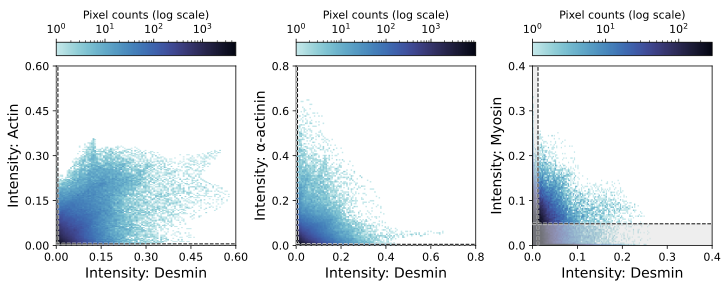

In [49]:
savepath = "../../figures/3f"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)